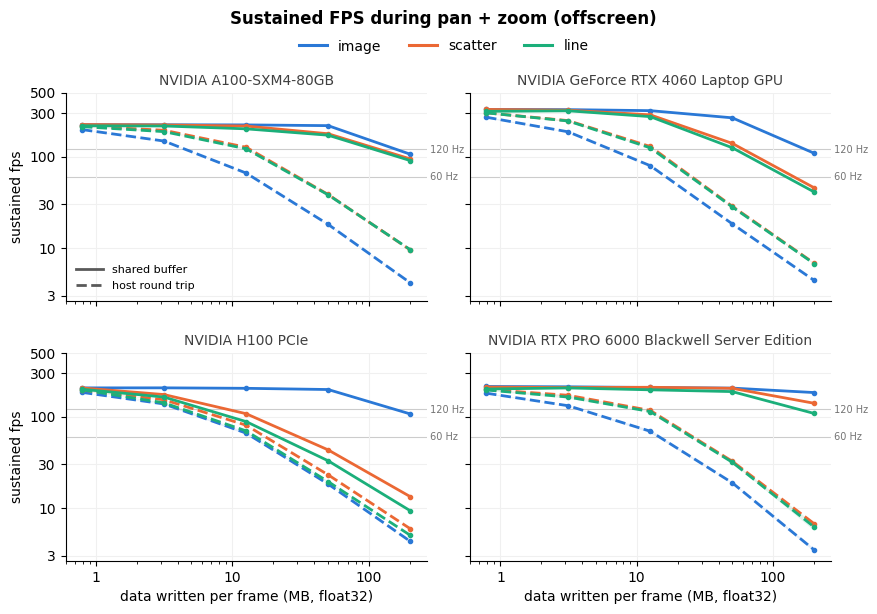

In [10]:
import glob

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

RESULTS = "offscreen-bench/results/panzoom_offscreen_*.csv"
MODE = "panzoom"
PRIMITIVES = {"image": "#2a78d6", "scatter": "#eb6834", "line": "#1baf7a"}
BACKENDS = {"shared": ("shared buffer", "-"), "naive": ("host round trip", "--")}
REF_HZ = [60, 120]
TITLE = "Sustained FPS during pan + zoom (offscreen)"

plt.rcParams.update({"font.size": 10})

df = pd.concat([pd.read_csv(f) for f in glob.glob(RESULTS)], ignore_index=True)
df = df.query("mode == @MODE").copy()

# float32 bytes per frame: image (H, W, 3), points (N, 3)
df["mb_per_frame"] = df["size"].where(df["primitive"] != "image", df["size"] ** 2) * 3 * 4 / 1e6

summary = (
    df.groupby(["gpu", "primitive", "backend", "size", "mb_per_frame"])["fps_median"]
    .agg(fps="mean", fps_std="std")
    .reset_index()
)

GPUS = sorted(summary["gpu"].unique())   # or set the order by hand

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey=True)
fig.subplots_adjust(top=0.86, bottom=0.08, left=0.08, right=0.93, hspace=0.25, wspace=0.12)

for ax, gpu in zip(axes.flat, GPUS):
    for hz in REF_HZ:
        ax.axhline(hz, color="0.8", lw=0.8, zorder=0)
        ax.text(1.0, hz, f" {hz} Hz", transform=ax.get_yaxis_transform(), va="center", fontsize=7, color="0.45")

    for primitive, color in PRIMITIVES.items():
        for backend, (_, ls) in BACKENDS.items():
            d = summary.query("gpu == @gpu and primitive == @primitive and backend == @backend").sort_values("mb_per_frame")
            if d.empty:
                continue
            ax.plot(d["mb_per_frame"], d["fps"], color=color, ls=ls, lw=2, marker="o", ms=3, zorder=3)
            ax.fill_between(d["mb_per_frame"], d["fps"] - d["fps_std"].fillna(0), d["fps"] + d["fps_std"].fillna(0),
                            color=color, alpha=0.12, lw=0, zorder=2)

    ax.set_title(gpu, fontsize=10, color="0.25")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(True, which="major", color="0.94", lw=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

ax = axes[0, 0]
ax.set_yticks([3, 10, 30, 100, 300, 500])
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))

for a in axes[1, :]:
    a.set_xlabel("data written per frame (MB, float32)")
for a in axes[:, 0]:
    a.set_ylabel("sustained fps")

# legends: color = primitive (top), line style = backend (first panel)
prim_handles = [plt.Line2D([], [], color=c, lw=2.2) for c in PRIMITIVES.values()]
back_handles = [plt.Line2D([], [], color="0.35", lw=2, ls=ls) for _, ls in BACKENDS.values()]
fig.legend(prim_handles, list(PRIMITIVES), loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.97))
axes[0, 0].legend(back_handles, [l for l, _ in BACKENDS.values()], loc="lower left", frameon=False,
                  handlelength=2.5, fontsize=8)

fig.text(0.5, 0.975, TITLE, ha="center", fontsize=12, fontweight="bold")

fig.savefig("offscreen-bench/results/fps_vs_mb_panzoom_4gpu.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
HIDE_X_TICKS = {3_000_000}  # avoid 3M/5M collision

In [16]:
def fmt_size(v, primitive):
    if primitive == "image":
        return f"{int(v)}²"
    if v in HIDE_X_TICKS:
        return ""
    return f"{v / 1e6:g}M" if v >= 1e6 else f"{v / 1e3:g}k"

In [18]:
GPU_NAMES = {
    "NVIDIA GeForce RTX 4060 Laptop GPU": "RTX 4060 (laptop)",
    "NVIDIA A100-SXM4-80GB": "A100",
    "NVIDIA H100 PCIe": "H100",
    "NVIDIA RTX PRO 6000 Blackwell Server Edition": "RTX Pro 6000",
}

speedup = (
    summary.pivot_table(index=["primitive", "mb_per_frame", "gpu"], columns="backend", values="fps")
    .assign(speedup=lambda t: t["shared"] / t["naive"])
    .reset_index()
    .pivot_table(index=["primitive", "mb_per_frame"], columns="gpu", values="speedup")
    [list(GPU_NAMES)]
)

speedup = speedup.reindex(list(PRIMITIVES), level="primitive")
speedup.index = pd.MultiIndex.from_tuples(
    [(p, f"{mb:.1f} MB") for p, mb in speedup.index],
    names=["primitive", "data / frame"],
)
speedup.columns = [GPU_NAMES[g] for g in speedup.columns]
speedup.columns.name = "shared ÷ naive"

speedup.style.format("{:.1f}×").background_gradient(cmap="Blues", axis=None, vmin=1)
